<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" width="240" alt="Query.Farm"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" width="150" alt="VGI"></a>

# Do more trees fix predictions beyond the training range?

A model can fit a smooth calibration curve well while behaving differently outside the input range it saw. We will train a LightGBM regressor through SQL on an **authored, noise-free calibration rule**, evaluate fixed points inside and beyond the training range, and verify the worker’s prediction contributions.

All data generation, fitting, prediction, explanation and error calculations happen in visible SQL through the actual worker. Python configures an isolated temporary registry and draws results. This is a designed model-behavior experiment, not a real sensor calibration or deployment benchmark. [Running instructions](README.md) pin the remote worker and published Haybarn environment.

## Choose the boosting budget

`N_ESTIMATORS` is an integer **1–200**, counting boosting iterations. The default is 20; the focused experiment uses 80. Learning rate, leaf budget, sample split, single-thread execution and random seed remain fixed. Edit the value, restart and run all. Every run gets a fresh temporary model registry, removed at cleanup.

In [1]:
N_ESTIMATORS = 20  # Boosting iterations; experiment: 80

In [2]:
import haybarn
import matplotlib.pyplot as plt

from notebook_support import chart, cleanup, configure, prose, theme

registry, previous_environment = configure(N_ESTIMATORS)
theme()
connection = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.displaylimit = 20
%sql connection

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/lane-2/vgi-lightgbm/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/lane-2/vgi-lightgbm/notebooks/pyproject.toml.

## Connect to the immutable remote worker

The literal companion launcher fetches revision `48e4b113f4f80615aa7d9a6d54434035a2425961`, verifies its source hashes, and runs its unchanged entry point with pinned published Python packages. It uses no local worker checkout and builds no SQL engine. See the README for Git, uv and OpenMP prerequisites. The model registry is local and disposable.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'lightgbm' (TYPE vgi, LOCATION 'python3 worker_launcher.py');
SET threads=1;
CREATE TABLE settings AS SELECT {{ N_ESTIMATORS }}::INTEGER AS n_estimators;

Running query in 'DuckDBPyConnection'

1 rows affected.

,Count


## Define the reference rule and split before fitting

The synthetic response is **2 mm + (3 mm/V × input voltage)**. Generate voltages from 0 to 12 V in 0.05 V steps. Within 0–8 V, reserve every fifth grid point whose integer ID is 2 modulo 5; all other points train the model. Voltages **greater than 8 V** form a separate extrapolation set and never enter training. The 8 V boundary remains a training point.

These held-out rows test this deterministic rule on a fixed grid. They are not a random sample, a confidence interval, measurement noise or evidence about real instruments. Model inputs include only `input_v`; the ID and reference response are explicitly excluded from features.

In [4]:
%%sql
CREATE TABLE observations AS
SELECT i::INTEGER AS sample_id, i/20.0 AS input_v, 2+3*i/20.0 AS reference_mm,
       CASE WHEN i>160 THEN 'Beyond training range'
            WHEN i%5=2 THEN 'Held out, within range'
            ELSE 'Training' END AS sample_role
FROM range(241) t(i);
SELECT sample_role, count(*) AS points, min(input_v) AS min_input_v,
       max(input_v) AS max_input_v, min(reference_mm) AS min_reference_mm,
       max(reference_mm) AS max_reference_mm
FROM observations GROUP BY sample_role ORDER BY min_input_v;

Running query in 'DuckDBPyConnection'

241 rows affected.

,sample_role,points,min_input_v,max_input_v,min_reference_mm,max_reference_mm
0,Training,129,0.00,8.00,2.00,26.00
1,"Held out, within range",32,0.10,7.85,2.30,25.55
2,Beyond training range,80,8.05,12.00,26.15,38.00


## Fit once and materialize the model summary

The worker receives only the training relation, sorted by ID. Use seven leaves, at least five rows per leaf, learning rate 0.1, one worker thread and seed zero. Training returns a native LightGBM model BLOB and stores the named model in this run’s temporary registry.

`CREATE TABLE AS SELECT` executes the stateful fit before any DataFrame capture, avoiding repeated training during display. A training score alone will not answer the extrapolation question; we evaluate all three subsets next.

In [5]:
%%sql
CREATE TABLE fitted AS
SELECT * FROM lightgbm.fit(
    (SELECT sample_id,input_v,reference_mm FROM observations
     WHERE sample_role='Training' ORDER BY sample_id),
    model_name := 'calibration', estimator := 'lgbm_regressor',
    target := 'reference_mm', id := 'sample_id',
    params := '{"n_estimators":{{ N_ESTIMATORS }},"num_leaves":7,"min_child_samples":5,"learning_rate":0.1,"n_jobs":1,"random_state":0}');
SELECT model_name, task, n_samples, n_features, features,
       octet_length(model) AS model_bytes FROM fitted;

Running query in 'DuckDBPyConnection'

1 rows affected.

,model_name,task,n_samples,n_features,features,model_bytes
0,calibration,regression,129,1,[input_v],18217


## Score the same fixed grid in every run

Prediction receives IDs and voltage only. Join back to the held-out reference after the worker returns; this prevents target leakage. Mean absolute error is in **millimetres**, with separate denominators for training, in-range holdout and beyond-range rows. A flat prediction outside the training range is an observed model behavior, not a claim that the synthetic reference becomes flat.

In [6]:
%%sql
CREATE TABLE predicted AS
SELECT * FROM lightgbm.predict(
    (SELECT sample_id,input_v FROM observations ORDER BY sample_id),
    model_name := 'calibration', id := 'sample_id');
CREATE TABLE evaluation AS
SELECT o.*, p.prediction AS predicted_mm, p.prediction-o.reference_mm AS error_mm,
       abs(p.prediction-o.reference_mm) AS absolute_error_mm
FROM observations o JOIN predicted p USING(sample_id);
CREATE TABLE metrics AS
SELECT sample_role, count(*) AS points, avg(absolute_error_mm) AS mae_mm,
       sqrt(avg(error_mm*error_mm)) AS rmse_mm,
       min(predicted_mm) AS min_prediction_mm, max(predicted_mm) AS max_prediction_mm,
       min(reference_mm) AS min_reference_mm, max(reference_mm) AS max_reference_mm
FROM evaluation GROUP BY sample_role;
SELECT sample_role,points,round(mae_mm,4) AS mae_mm,round(rmse_mm,4) AS rmse_mm,
       round(max_prediction_mm-min_prediction_mm,6) AS prediction_span_mm
FROM metrics ORDER BY CASE sample_role WHEN 'Training' THEN 1 WHEN 'Held out, within range' THEN 2 ELSE 3 END;

Running query in 'DuckDBPyConnection'

241 rows affected.

241 rows affected.

3 rows affected.

,sample_role,points,mae_mm,rmse_mm,prediction_span_mm
0,Training,129,0.7650,0.9265,19.335563
1,"Held out, within range",32,0.7586,0.9059,19.335563
2,Beyond training range,80,8.3934,9.0800,0.000000


In [7]:
%%sql curve_frame <<
SELECT * FROM evaluation ORDER BY input_v;

Running query in 'DuckDBPyConnection'

In [8]:
%%sql metrics_frame <<
SELECT * FROM metrics ORDER BY CASE sample_role WHEN 'Training' THEN 1 WHEN 'Held out, within range' THEN 2 ELSE 3 END;

Running query in 'DuckDBPyConnection'

In [9]:
inside = metrics_frame[metrics_frame.sample_role == "Held out, within range"].iloc[0]
outside = metrics_frame[metrics_frame.sample_role == "Beyond training range"].iloc[0]
prose(
    f"With **{N_ESTIMATORS} boosting iterations**, in-range holdout MAE is **{inside.mae_mm:.3f} mm** "
    f"over **{inside.points:.0f} points**. Beyond-range MAE is **{outside.mae_mm:.3f} mm** "
    f"over **{outside.points:.0f} points**. Across that outside set, predictions span "
    f"**{outside.max_prediction_mm - outside.min_prediction_mm:.6f} mm**, while the authored reference spans "
    f"**{outside.max_reference_mm - outside.min_reference_mm:.2f} mm**. "
    "Every run uses the same grid; the result describes this authored rule, not real-world performance."
)

With **20 boosting iterations**, in-range holdout MAE is **0.759 mm** over **32 points**. Beyond-range MAE is **8.393 mm** over **80 points**. Across that outside set, predictions span **0.000000 mm**, while the authored reference spans **11.85 mm**. Every run uses the same grid; the result describes this authored rule, not real-world performance.

findfont: Failed to find font weight semibold for Arial, now using 700.


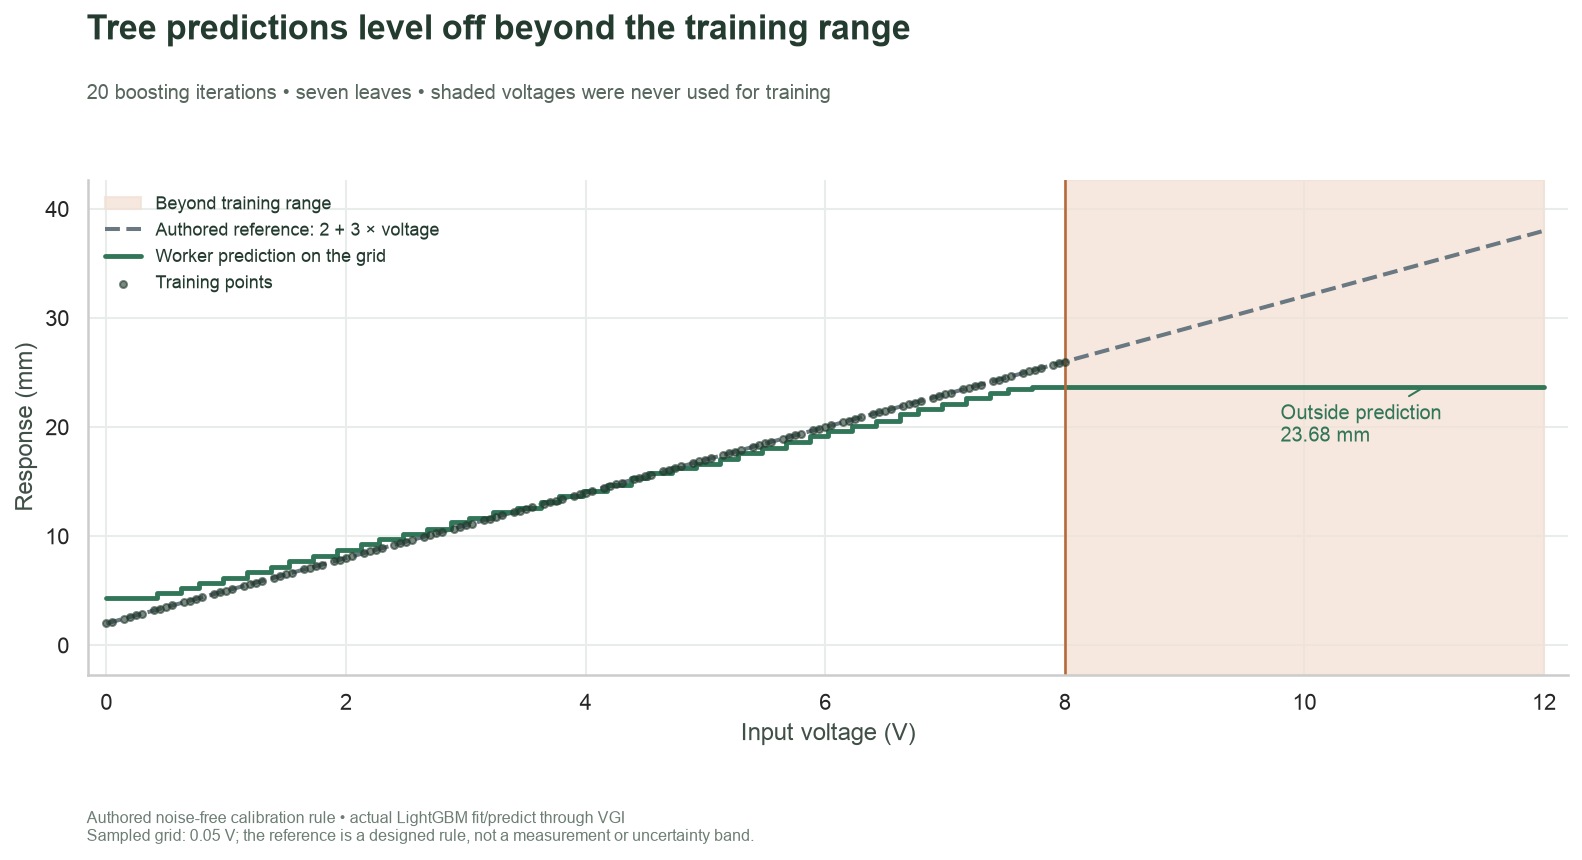

In [10]:
fig, ax = plt.subplots(figsize=(11.3, 6))
ax.axvspan(8, 12, color="#F3E1D5", alpha=0.75, label="Beyond training range")
ax.plot(
    curve_frame.input_v,
    curve_frame.reference_mm,
    color="#6A7882",
    ls="--",
    lw=2,
    label="Authored reference: 2 + 3 × voltage",
)
ax.plot(
    curve_frame.input_v,
    curve_frame.predicted_mm,
    color="#327659",
    lw=2.4,
    drawstyle="steps-mid",
    label="Worker prediction on the grid",
)
training = curve_frame[curve_frame.sample_role == "Training"]
ax.scatter(
    training.input_v,
    training.reference_mm,
    color="#243B2F",
    s=12,
    alpha=0.6,
    label="Training points",
    zorder=3,
)
ax.axvline(8, color="#B5693B", lw=1.3)
ax.set(xlabel="Input voltage (V)", ylabel="Response (mm)", xlim=(-0.15, 12.2))
ax.margins(y=0.13)
ax.legend(loc="upper left", fontsize=9)
ax.annotate(
    f"Outside prediction\n{outside.max_prediction_mm:.2f} mm",
    xy=(11, outside.max_prediction_mm),
    xytext=(9.8, outside.max_prediction_mm - 5),
    arrowprops={"arrowstyle": "-", "color": "#327659"},
    color="#327659",
    fontsize=10,
)
chart(
    fig,
    "Tree predictions level off beyond the training range",
    f"{N_ESTIMATORS} boosting iterations • seven leaves • shaded voltages were never used for training",
    "Authored noise-free calibration rule • actual LightGBM fit/predict through VGI\n"
    "Sampled grid: 0.05 V; the reference is a designed rule, not a measurement or uncertainty band.",
)

For an ordinary tree regressor, numeric splits route voltages above every training split into terminal leaves. Adding trees can change those leaf values, while the beyond-range response remains flat for this one-feature experiment. The next chart compares error by evaluation subset; the training bar is descriptive and must not be read as held-out performance.

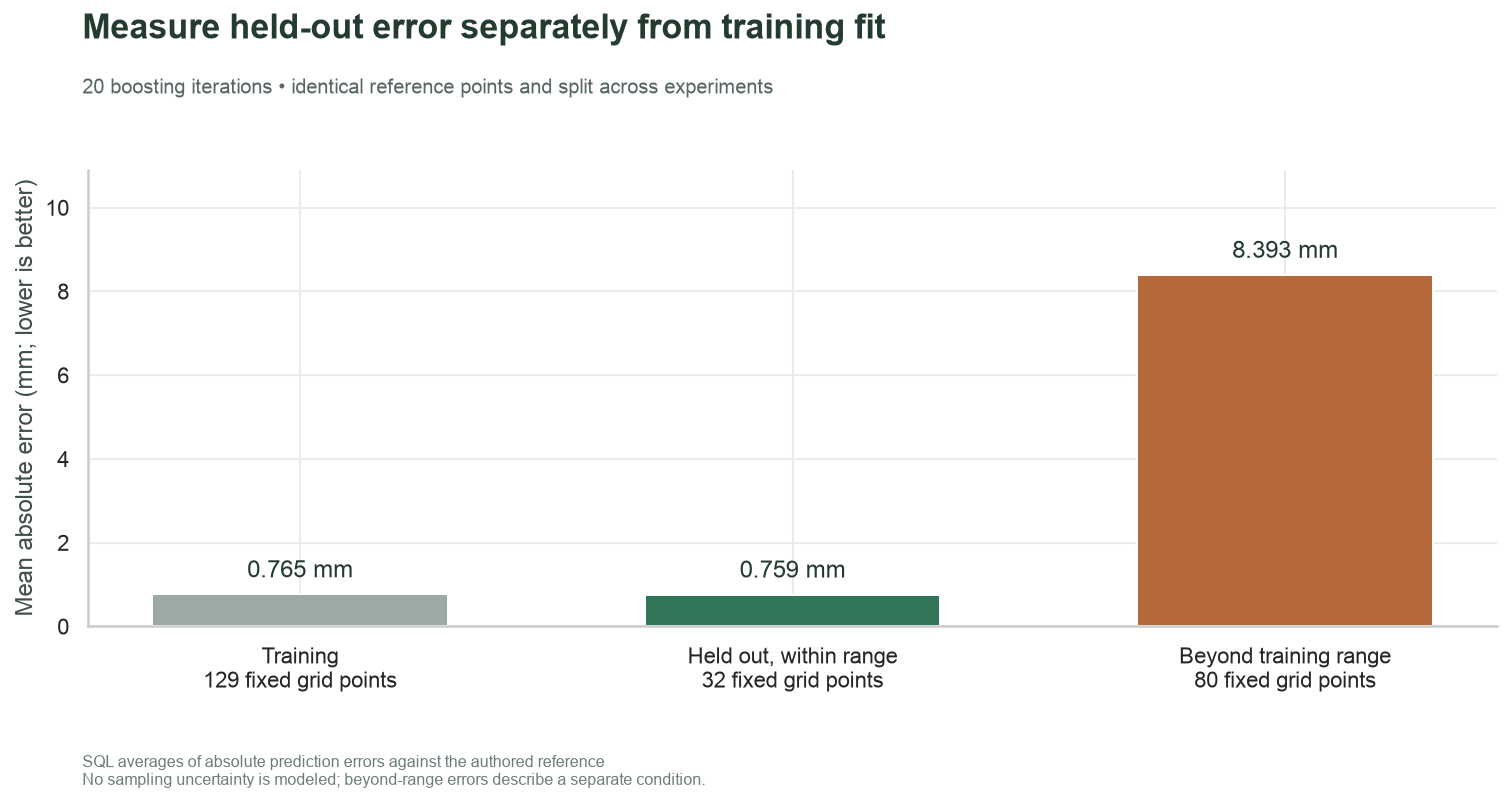

In [11]:
fig, ax = plt.subplots(figsize=(10.8, 5.6))
colors = ["#9BAAA2", "#327659", "#B5693B"]
bars = ax.bar(range(len(metrics_frame)), metrics_frame.mae_mm, color=colors, width=0.60)
ax.bar_label(bars, labels=[f"{v:.3f} mm" for v in metrics_frame.mae_mm], padding=6)
ax.set_xticks(
    range(len(metrics_frame)),
    [f"{r.sample_role}\n{r.points:.0f} fixed grid points" for r in metrics_frame.itertuples()],
)
ax.set_ylabel("Mean absolute error (mm; lower is better)")
ax.set_ylim(0, float(metrics_frame.mae_mm.max()) * 1.3)
chart(
    fig,
    "Measure held-out error separately from training fit",
    f"{N_ESTIMATORS} boosting iterations • identical reference points and split across experiments",
    "SQL averages of absolute prediction errors against the authored reference\n"
    "No sampling uncertainty is modeled; beyond-range errors describe a separate condition.",
)

## Verify prediction contributions without calling them causes

The worker’s `explain` function returns a base value and per-feature contributions. For this regression objective, **base + sum of contributions = prediction**, in millimetres. It explains the fitted model’s output, not a physical cause or confidence interval. With one feature, there is one contribution per row; the base is added once, not once per feature.

In [12]:
%%sql
CREATE TABLE explanations AS
SELECT * FROM lightgbm.explain(
    (SELECT sample_id,input_v FROM observations ORDER BY sample_id),
    model_name := 'calibration',id := 'sample_id');
CREATE TABLE reconstructed AS
SELECT sample_id,min(base_value)+sum(shap_value) AS reconstructed_mm,
       max(base_value)-min(base_value) AS base_span_mm
FROM explanations GROUP BY sample_id;
SELECT e.sample_id,input_v,round(base_value,3) AS base_mm,
       round(shap_value,3) AS contribution_mm,round(predicted_mm,3) AS predicted_mm,
       round(reference_mm,3) AS reference_mm
FROM explanations e JOIN evaluation v USING(sample_id)
WHERE e.sample_id IN (0,80,160,200,240) ORDER BY e.sample_id;

Running query in 'DuckDBPyConnection'

241 rows affected.

241 rows affected.

,sample_id,input_v,base_mm,contribution_mm,predicted_mm,reference_mm
0,0,0.0,14.019,-9.673,4.346,2.0
1,80,4.0,14.019,0.153,14.171,14.0
2,160,8.0,14.019,9.663,23.682,26.0
3,200,10.0,14.019,9.663,23.682,32.0
4,240,12.0,14.019,9.663,23.682,38.0


## Check contracts, separation and arithmetic

Verify cardinality and ID coverage before trusting aggregate errors. Then compare contribution reconstruction with predictions, check that fitting used one feature and only the designated training rows, and confirm the beyond-range plateau directly. No check demands a particular score or that more iterations must improve every error.

In [13]:
%%sql
CREATE TABLE checks AS
SELECT 'Source IDs are unique' AS check_name,count(*)=count(DISTINCT sample_id) AS passed FROM observations
UNION ALL SELECT 'Predictions preserve all IDs exactly once',
    (SELECT count(*) FROM predicted)=(SELECT count(*) FROM observations)
    AND (SELECT count(*) FROM predicted)=(SELECT count(DISTINCT sample_id) FROM predicted)
    AND NOT EXISTS(SELECT sample_id FROM observations EXCEPT SELECT sample_id FROM predicted)
UNION ALL SELECT 'Model uses only training rows and one feature',
    count(*)=1 AND min(n_samples)=(SELECT count(*) FROM observations WHERE sample_role='Training')
    AND min(n_features)=1 AND min(features) = ['input_v'] FROM fitted
UNION ALL SELECT 'Training and outside ranges are disjoint',
    (SELECT max(input_v) FROM observations WHERE sample_role='Training')<
    (SELECT min(input_v) FROM observations WHERE sample_role='Beyond training range')
UNION ALL SELECT 'Evaluation partition preserves row count',
    (SELECT sum(points) FROM metrics)=(SELECT count(*) FROM observations)
UNION ALL SELECT 'Errors are finite and RMSE bounds MAE',
    bool_and(isfinite(mae_mm) AND isfinite(rmse_mm) AND mae_mm>=0 AND rmse_mm+1e-12>=mae_mm) FROM metrics
UNION ALL SELECT 'Beyond-range predictions share terminal-leaf output',
    max_prediction_mm-min_prediction_mm<1e-10 FROM metrics WHERE sample_role='Beyond training range'
UNION ALL SELECT 'Explanation IDs cover all prediction rows',
    (SELECT count(*) FROM reconstructed)=(SELECT count(*) FROM predicted)
    AND NOT EXISTS(SELECT sample_id FROM predicted EXCEPT SELECT sample_id FROM reconstructed)
UNION ALL SELECT 'Contribution base is consistent per row',bool_and(base_span_mm<1e-10) FROM reconstructed
UNION ALL SELECT 'Contribution sums recover regression predictions',
    max(abs(reconstructed_mm-prediction))<1e-8 FROM reconstructed JOIN predicted USING(sample_id);
SELECT check_name, CASE WHEN passed THEN 'PASS' ELSE error(check_name) END AS result FROM checks;

Running query in 'DuckDBPyConnection'

10 rows affected.

,check_name,result
0,Source IDs are unique,PASS
1,Predictions preserve all IDs exactly once,PASS
2,Model uses only training rows and one feature,PASS
3,Training and outside ranges are disjoint,PASS
4,Evaluation partition preserves row count,PASS
5,Errors are finite and RMSE bounds MAE,PASS
6,Beyond-range predictions share terminal-leaf o...,PASS
7,Explanation IDs cover all prediction rows,PASS
8,Contribution base is consistent per row,PASS
9,Contribution sums recover regression predictions,PASS


## Focused experiment: add trees, keep the data fixed

Change **`N_ESTIMATORS` from 20 to 80**, restart and run all. Predict improved fit to the in-range curve, while the response above 8 V remains flat. Compare both held-out MAEs, the outside plateau level and the contribution-reconstruction check. Every reference point and subset remains fixed, so the experiment changes one model setting.

More boosting may reduce underfitting; it does not turn tree leaves into the authored linear continuation. This single comparison is not hyperparameter tuning, a statistical performance guarantee or a reason to deploy a real calibration model. Reset **20** for the default; the README provides a separate-output experiment command. Cleanup removes this run’s temporary model registry.

In [14]:
connection.close()
cleanup(registry, previous_environment)

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" width="240" alt="Query.Farm"></a>

[Query.Farm](https://query.farm/) · [Vector Gateway Interface](https://query.farm/vgi/)